# 🐧 Modul 4 — Praktikum Variabel Acak & LLM Sampling

### Studi Kasus: Palmer Penguins Dataset (Kaggle) + Demo LLM Temperature

**Mata Kuliah:** Statistika & Probabilitas (TIF1501)  
**Program Studi:** Teknik Informatika (55201) · FTI · Uniska MAB Banjarmasin  
**Semester:** 5 · 3 SKS

---

## 🎯 Tujuan Pembelajaran

Setelah menyelesaikan notebook ini, Anda akan mampu:

1. **Membedakan** variabel acak diskret dan kontinu dari data nyata.
2. **Menghitung** nilai harapan E(X) dan variansi Var(X).
3. **Memvisualisasikan** PMF, PDF, dan CDF dengan scipy.stats.
4. **Menjelaskan** peran sampling dalam Generative AI (temperature LLM).

---

## 📋 Alur Notebook

| Bagian | Isi | Waktu |
|--------|-----|-------|
| **A** | Setup & Load Palmer Penguins | 10 menit |
| **B** | Klasifikasi Variabel Diskret vs Kontinu (LATIHAN) | 15 menit |
| **C** | Menghitung E(X) dan Var(X) | 15 menit |
| **D** | PMF: Variabel Diskret dengan scipy.stats | 10 menit |
| **E** | PDF: Variabel Kontinu dengan Normal Fit | 10 menit |
| **F** | CDF Empiris vs Teoritis | 10 menit |
| **G** | LLM Temperature Sampling (LATIHAN UTAMA) | 15 menit |
| **H** | Refleksi & Submit ke GitHub | 5 menit |

**Total: ± 90 menit**

---

## 💡 Kenapa Palmer Penguins?

Dataset **Palmer Penguins** adalah dataset modern (2020) yang muncul sebagai alternatif Iris di dunia Data Science. Berisi data 344 penguin dari 3 spesies (Adelie, Chinstrap, Gentoo) yang diobservasi di Palmer Station, Antartika oleh Dr. Kristen Gorman.

- ✅ Berisi **variabel diskret** (species, island, sex, year) dan **kontinu** (bill length/depth, flipper length, body mass)
- ✅ Ukuran manageable (344 baris) — cepat untuk eksperimen
- ✅ Tersedia gratis dari repository publik allisonhorst
- ✅ Populer di Kaggle & di R/Python community
- ✅ Cocok sekali untuk demonstrasi PMF, PDF, CDF sekaligus


---

# 🔧 A. Setup & Load Palmer Penguins

## A.1 Import Library


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# scipy untuk PMF, PDF, CDF
from scipy import stats
from scipy.stats import norm, binom, poisson, expon

# Set style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Library siap!")
print(f"NumPy   : {np.__version__}")
print(f"pandas  : {pd.__version__}")
print(f"SciPy   : {stats.__name__.split('.')[0]}")


Library siap!
NumPy   : 2.1.3
pandas  : 2.2.3
SciPy   : scipy


## A.2 Load Palmer Penguins dari URL Kaggle-style


In [2]:
# URL dataset Palmer Penguins (dari repository allisonhorst)
url = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"

df = pd.read_csv(url)

print(f"Dataset berhasil dimuat: {df.shape[0]} baris × {df.shape[1]} kolom")
print(f"\nKolom yang tersedia:")
for col in df.columns:
    print(f"  • {col}")

df.head()


Dataset berhasil dimuat: 344 baris × 8 kolom

Kolom yang tersedia:
  • species
  • island
  • bill_length_mm
  • bill_depth_mm
  • flipper_length_mm
  • body_mass_g
  • sex
  • year


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


## A.3 Data Cleaning: Buang Missing Values


In [3]:
# Cek missing values
print("Missing values per kolom:")
print(df.isnull().sum())

# Drop rows dengan missing (agar analisis lebih clean)
df_clean = df.dropna().reset_index(drop=True)
print(f"\nSetelah drop missing: {len(df_clean)} baris")

# Preview data bersih
df_clean.head()


Missing values per kolom:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

Setelah drop missing: 333 baris


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007


---

# 🧭 B. Klasifikasi Variabel: Diskret vs Kontinu

**Tujuan Pembelajaran 1** — Identifikasi jenis setiap kolom.

## B.1 Konsep Kunci

| Ciri | Diskret | Kontinu |
|------|---------|---------|
| Nilai | Countable (bisa dihitung) | Uncountable (tak terputus) |
| Contoh | 0, 1, 2, 3, ... | 3.14, 2.718, ... |
| Probabilitas | P(X=x) langsung | P(X=c) = 0! Pakai interval |
| Deskripsi | PMF | PDF |


In [4]:
# Cek tipe data pandas + jumlah nilai unik
info = pd.DataFrame({
    'dtype': df_clean.dtypes,
    'n_unique': df_clean.nunique(),
    'sample_values': [df_clean[c].unique()[:5].tolist() for c in df_clean.columns],
})
print("Informasi per kolom:")
info


Informasi per kolom:


,dtype,n_unique,sample_values
species,object,3,"[Adelie, Gentoo, Chinstrap]"
island,object,3,"[Torgersen, Biscoe, Dream]"
bill_length_mm,float64,163,"[39.1, 39.5, 40.3, 36.7, 39.3]"
bill_depth_mm,float64,79,"[18.7, 17.4, 18.0, 19.3, 20.6]"
flipper_length_mm,float64,54,"[181.0, 186.0, 195.0, 193.0, 190.0]"
body_mass_g,float64,93,"[3750.0, 3800.0, 3250.0, 3450.0, 3650.0]"
sex,object,2,"[male, female]"
year,int64,3,"[2007, 2008, 2009]"


## B.2 Klasifikasi (Kunci Jawaban)

| Kolom | Jumlah unique | Jenis | Alasan |
|-------|:-:|-------|--------|
| species | 3 | **DISKRET** | Kategori tanpa urutan (Adelie/Chinstrap/Gentoo) |
| island | 3 | **DISKRET** | 3 pulau berbeda |
| bill_length_mm | banyak | **KONTINU** | Panjang paruh — bisa 39.1, 39.15, 39.152... |
| bill_depth_mm | banyak | **KONTINU** | Kedalaman paruh |
| flipper_length_mm | ~55 | **DISKRET** teknis, tapi diperlakukan kontinu | Diukur dalam mm bulat, tapi asalnya kontinu |
| body_mass_g | ~94 | **DISKRET** teknis, kontinu semantik | Berat badan — asalnya kontinu, dibulatkan |
| sex | 2 | **DISKRET** | male/female |
| year | 3 | **DISKRET** | 2007, 2008, 2009 |


## B.3 Latihan Anda: Klasifikasi 5 Variabel Baru

Bayangkan menambah kolom baru ke dataset. Klasifikasi (isi cell markdown di bawah):

1. `avg_temperature_C` = suhu rata-rata di lokasi observasi (°C)
2. `n_offspring` = jumlah anak yang dihasilkan
3. `is_healthy` = 1 (sehat) atau 0 (sakit)
4. `gps_latitude` = koordinat lintang
5. `chick_age_days` = umur anak (hari)

### ✏️ Jawaban Anda:
- **avg_temperature_C**: _(diskret / kontinu, alasan?)_
- **n_offspring**: _..._
- **is_healthy**: _..._
- **gps_latitude**: _..._
- **chick_age_days**: _..._


---

# 📊 C. Nilai Harapan E(X) dan Variansi Var(X)

**Tujuan Pembelajaran 2** — Hitung E(X) dan Var(X) dari data.

## C.1 Estimator dari Data

Dari sampel data, kita estimasi:

$$\hat{E}(X) = \bar{x} = \frac{1}{n}\sum_{i=1}^n x_i \qquad \hat{Var}(X) = s^2 = \frac{1}{n-1}\sum_{i=1}^n (x_i - \bar{x})^2$$


In [5]:
# Hitung E(X) dan Var(X) untuk body_mass_g
X = df_clean['body_mass_g']

E_X    = X.mean()               # E(X)
Var_X  = X.var(ddof=1)          # Var(X) - sample variance
SD_X   = X.std(ddof=1)          # standar deviasi

# Verifikasi dengan formula manual
E_X_manual = X.sum() / len(X)
Var_X_manual = ((X - E_X_manual)**2).sum() / (len(X) - 1)

print("=" * 55)
print(f"Variabel: body_mass_g (berat penguin dalam gram)")
print("=" * 55)
print(f"n            = {len(X)}")
print(f"E(X)         = {E_X:.2f}  gram    (manual: {E_X_manual:.2f})")
print(f"Var(X)       = {Var_X:.2f} gram²  (manual: {Var_X_manual:.2f})")
print(f"σ = √Var(X)  = {SD_X:.2f}  gram")
print(f"\n→ Rata-rata berat penguin ≈ {E_X:.0f} gram")
print(f"→ Standar deviasi ≈ {SD_X:.0f} gram")


Variabel: body_mass_g (berat penguin dalam gram)
n            = 333
E(X)         = 4207.06  gram    (manual: 4207.06)
Var(X)       = 648372.49 gram²  (manual: 648372.49)
σ = √Var(X)  = 805.22  gram

→ Rata-rata berat penguin ≈ 4207 gram
→ Standar deviasi ≈ 805 gram


## C.2 E(X) dan Var(X) per Spesies

Menarik dilihat: apakah E(X) beda per spesies?


Statistik body_mass_g per spesies:
             n     mean        var     std     min     max
species                                                   
Adelie     146  3706.16  210332.43  458.62  2850.0  4775.0
Chinstrap   68  3733.09  147713.45  384.34  2700.0  4800.0
Gentoo     119  5092.44  251478.33  501.48  3950.0  6300.0


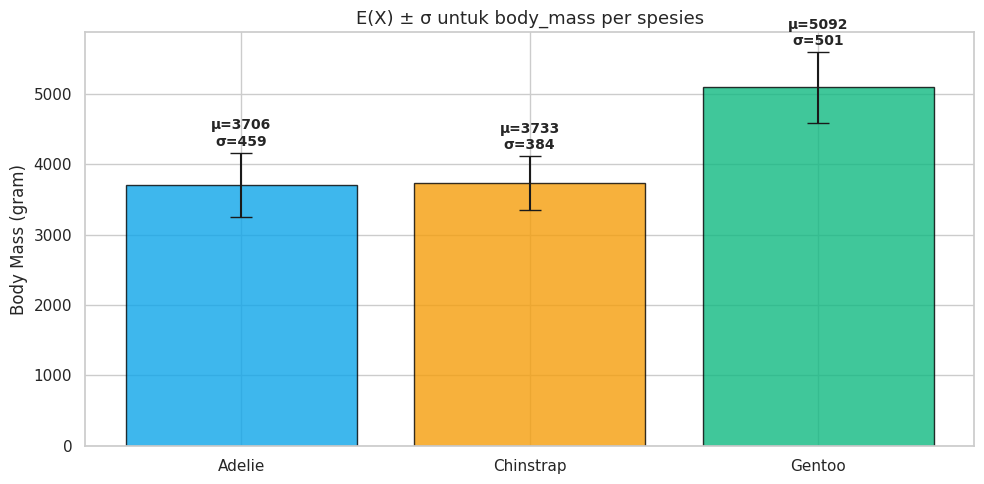

In [6]:
# Grup by species
stats_per_species = df_clean.groupby('species')['body_mass_g'].agg(
    n='count',
    mean='mean',
    var='var',
    std='std',
    min='min',
    max='max'
).round(2)

print("Statistik body_mass_g per spesies:")
print(stats_per_species)

# Visualisasi
fig, ax = plt.subplots(figsize=(10, 5))
species_list = stats_per_species.index.tolist()
means = stats_per_species['mean'].values
stds = stats_per_species['std'].values

ax.bar(species_list, means, yerr=stds, capsize=8,
       color=['#0EA5E9', '#F59E0B', '#10B981'],
       edgecolor='black', alpha=0.8)
ax.set_ylabel('Body Mass (gram)', fontsize=12)
ax.set_title('E(X) ± σ untuk body_mass per spesies', fontsize=13)
for i, (m, s) in enumerate(zip(means, stds)):
    ax.text(i, m + s + 100, f'μ={m:.0f}\nσ={s:.0f}',
            ha='center', fontweight='bold', fontsize=10)
plt.tight_layout()
plt.show()


> 💡 **Insight**: Gentoo penguin secara rata-rata jauh lebih berat (~5000g) dibanding Adelie & Chinstrap (~3700g). Var(X) juga berbeda — Gentoo lebih bervariasi.


## C.3 Verifikasi Sifat E(X): Linearitas


In [7]:
# Sifat: E(cX + b) = c·E(X) + b
c, b = 2.5, 100

Y = c * X + b   # transformasi linear

E_Y_manual = c * E_X + b        # dari sifat
E_Y_direct = Y.mean()            # hitung langsung

print(f"E(X)                = {E_X:.2f}")
print(f"E({c}·X + {b}) via sifat  = {E_Y_manual:.2f}")
print(f"E({c}·X + {b}) hitung     = {E_Y_direct:.2f}")
print(f"Selisih: {abs(E_Y_manual - E_Y_direct):.6f} (≈ 0 → sifat verified!)\n")

# Sifat: Var(cX + b) = c² · Var(X)
Var_Y_manual = c**2 * Var_X
Var_Y_direct = Y.var(ddof=1)

print(f"Var(X)                    = {Var_X:.2f}")
print(f"Var({c}·X + {b}) via sifat    = {Var_Y_manual:.2f}")
print(f"Var({c}·X + {b}) hitung       = {Var_Y_direct:.2f}")
print(f"Selisih: {abs(Var_Y_manual - Var_Y_direct):.6f} (≈ 0 → sifat verified!)")


E(X)                = 4207.06
E(2.5·X + 100) via sifat  = 10617.64
E(2.5·X + 100) hitung     = 10617.64
Selisih: 0.000000 (≈ 0 → sifat verified!)

Var(X)                    = 648372.49
Var(2.5·X + 100) via sifat    = 4052328.05
Var(2.5·X + 100) hitung       = 4052328.05
Selisih: 0.000000 (≈ 0 → sifat verified!)


---

# 🎯 D. PMF: Probability Mass Function untuk Variabel Diskret

**Tujuan Pembelajaran 3** — Visualisasi distribusi diskret.

## D.1 PMF Empiris dari Data


PMF (empiris) untuk kolom 'species':
  P(species = Adelie      ) = 0.4384
  P(species = Gentoo      ) = 0.3574
  P(species = Chinstrap   ) = 0.2042
  Σ P = 1.0000  ✓ (harus 1.0)


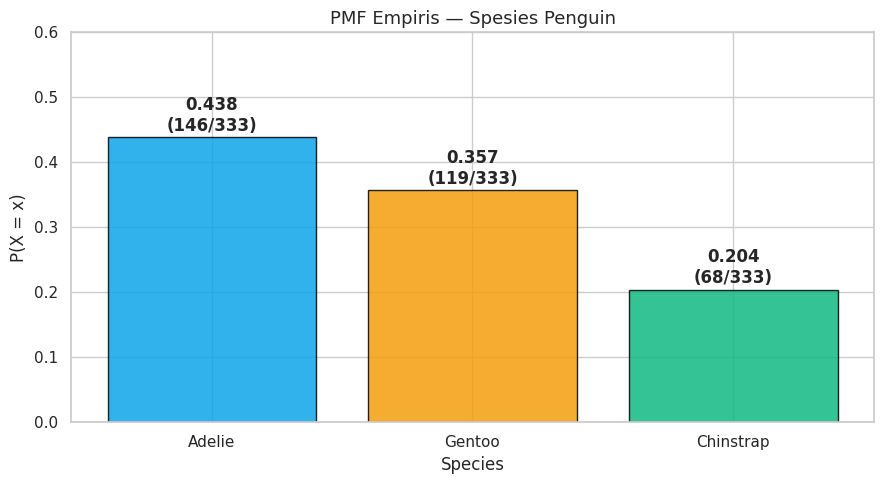

In [8]:
# PMF spesies
species_counts = df_clean['species'].value_counts()
species_pmf = species_counts / len(df_clean)

print("PMF (empiris) untuk kolom 'species':")
for spec, prob in species_pmf.items():
    print(f"  P(species = {spec:12s}) = {prob:.4f}")
print(f"  Σ P = {species_pmf.sum():.4f}  ✓ (harus 1.0)")

# Visualisasi
fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#0EA5E9', '#F59E0B', '#10B981']
ax.bar(species_pmf.index, species_pmf.values, color=colors,
       edgecolor='black', alpha=0.85)
ax.set_ylabel('P(X = x)', fontsize=12)
ax.set_xlabel('Species', fontsize=12)
ax.set_title('PMF Empiris — Spesies Penguin', fontsize=13)
for i, (spec, p) in enumerate(species_pmf.items()):
    ax.text(i, p + 0.01, f'{p:.3f}\n({species_counts[spec]}/{len(df_clean)})',
            ha='center', fontweight='bold')
ax.set_ylim(0, 0.6)
plt.tight_layout()
plt.show()


## D.2 PMF Teoritis dengan scipy.stats: Distribusi Binomial

Skenario: dari 10 penguin acak, berapa peluang tepat k = Gentoo? Ini distribusi **Binomial(n=10, p)**.


p = P(Gentoo) = 0.3574
n trials     = 10

PMF Binomial(n=10, p=0.357):
  P(X =  0) = 0.0120
  P(X =  1) = 0.0668
  P(X =  2) = 0.1672
  P(X =  3) = 0.2479
  P(X =  4) = 0.2412
  P(X =  5) = 0.1610
  P(X =  6) = 0.0746
  P(X =  7) = 0.0237
  P(X =  8) = 0.0049
  P(X =  9) = 0.0006
  P(X = 10) = 0.0000


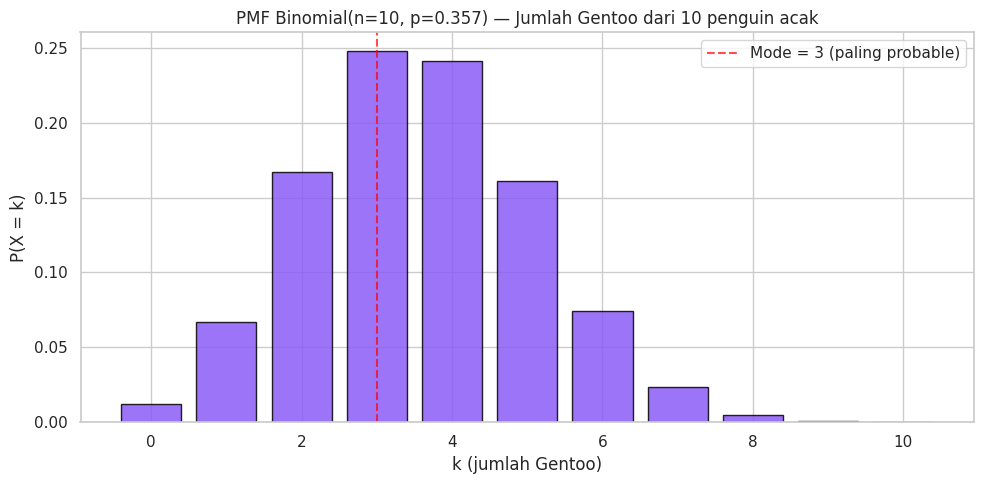


E(X) Binomial = n × p = 10 × 0.357 = 3.574


In [9]:
# Peluang seekor penguin Gentoo (dari data)
p_gentoo = species_pmf['Gentoo']
n_trials = 10

print(f"p = P(Gentoo) = {p_gentoo:.4f}")
print(f"n trials     = {n_trials}\n")

# PMF Binomial: peluang k = 0, 1, ..., n Gentoo
k_values = np.arange(0, n_trials + 1)
pmf_binom = binom.pmf(k_values, n=n_trials, p=p_gentoo)

# Tampilkan
print(f"PMF Binomial(n={n_trials}, p={p_gentoo:.3f}):")
for k, p in zip(k_values, pmf_binom):
    print(f"  P(X = {k:2d}) = {p:.4f}")

# Visualisasi
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(k_values, pmf_binom, color='#8B5CF6', edgecolor='black', alpha=0.85)
ax.set_xlabel('k (jumlah Gentoo)', fontsize=12)
ax.set_ylabel('P(X = k)', fontsize=12)
ax.set_title(f'PMF Binomial(n={n_trials}, p={p_gentoo:.3f}) — Jumlah Gentoo dari 10 penguin acak',
             fontsize=12)
# Highlight mode (paling probable)
mode_k = k_values[pmf_binom.argmax()]
ax.axvline(mode_k, color='red', linestyle='--', alpha=0.7,
           label=f'Mode = {mode_k} (paling probable)')
ax.legend()
plt.tight_layout()
plt.show()

# Verifikasi E(X) Binomial = n × p
E_binom = n_trials * p_gentoo
print(f"\nE(X) Binomial = n × p = {n_trials} × {p_gentoo:.3f} = {E_binom:.3f}")


---

# 📈 E. PDF: Probability Density Function untuk Variabel Kontinu

**Tujuan Pembelajaran 3** — Fit distribusi kontinu ke data.

## E.1 Histogram (Estimasi Empiris PDF)


Data Gentoo body_mass: n = 119
Range: 3950.0 - 6300.0 gram

Fit Normal:
  μ (mean) = 5092.44
  σ (std)  = 499.36


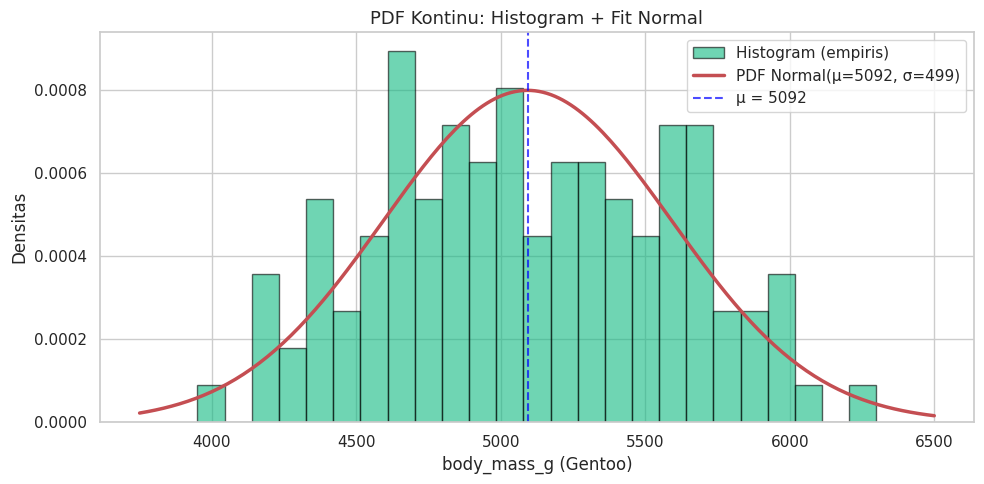

In [10]:
# Ambil body_mass Gentoo saja (agar distribusi lebih bersih)
gentoo_mass = df_clean[df_clean['species'] == 'Gentoo']['body_mass_g'].values

print(f"Data Gentoo body_mass: n = {len(gentoo_mass)}")
print(f"Range: {gentoo_mass.min()} - {gentoo_mass.max()} gram")

# Fit distribusi Normal
mu, sigma = norm.fit(gentoo_mass)
print(f"\nFit Normal:")
print(f"  μ (mean) = {mu:.2f}")
print(f"  σ (std)  = {sigma:.2f}")

# Visualisasi: histogram + PDF fit
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(gentoo_mass, bins=25, density=True, alpha=0.6,
        color='#10B981', edgecolor='black', label='Histogram (empiris)')

# Plot PDF Normal
x_range = np.linspace(gentoo_mass.min() - 200, gentoo_mass.max() + 200, 200)
pdf_normal = norm.pdf(x_range, loc=mu, scale=sigma)
ax.plot(x_range, pdf_normal, 'r-', linewidth=2.5,
        label=f'PDF Normal(μ={mu:.0f}, σ={sigma:.0f})')

ax.axvline(mu, color='blue', linestyle='--', alpha=0.7, label=f'μ = {mu:.0f}')
ax.set_xlabel('body_mass_g (Gentoo)', fontsize=12)
ax.set_ylabel('Densitas', fontsize=12)
ax.set_title('PDF Kontinu: Histogram + Fit Normal', fontsize=13)
ax.legend()
plt.tight_layout()
plt.show()


## E.2 Perbedaan Penting: PDF ≠ Probabilitas!

Nilai PDF di suatu titik BUKAN probabilitas. Probabilitas hanya bermakna untuk **rentang**.


PDF di 5000: f(5000) = 0.000785   ← BUKAN probabilitas!

P(4500 ≤ X ≤ 5500) via CDF = 0.6751  (67.51%)
P(4500 ≤ X ≤ 5500) empiris = 0.6387  (63.87%)
Selisih: 0.0364


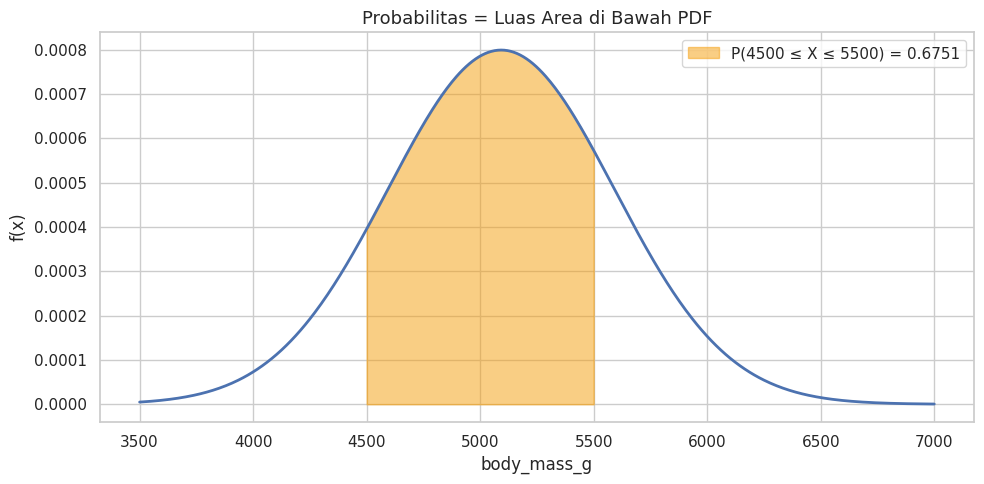

In [11]:
# Contoh: berapa P(4500 ≤ mass ≤ 5500) untuk Gentoo?
a, b = 4500, 5500

# Method 1: PDF nilai tunggal (BUKAN probabilitas!)
pdf_val = norm.pdf(5000, loc=mu, scale=sigma)
print(f"PDF di 5000: f(5000) = {pdf_val:.6f}   ← BUKAN probabilitas!")

# Method 2: Integral PDF (yang benar) — pakai CDF
prob_range = norm.cdf(b, loc=mu, scale=sigma) - norm.cdf(a, loc=mu, scale=sigma)
print(f"\nP({a} ≤ X ≤ {b}) via CDF = {prob_range:.4f}  ({prob_range*100:.2f}%)")

# Verifikasi dari data empiris
empirical = ((gentoo_mass >= a) & (gentoo_mass <= b)).mean()
print(f"P({a} ≤ X ≤ {b}) empiris = {empirical:.4f}  ({empirical*100:.2f}%)")
print(f"Selisih: {abs(prob_range - empirical):.4f}")

# Visualisasi area under curve
fig, ax = plt.subplots(figsize=(10, 5))
x_range = np.linspace(3500, 7000, 500)
pdf_range = norm.pdf(x_range, loc=mu, scale=sigma)
ax.plot(x_range, pdf_range, 'b-', linewidth=2)

# Shade area
x_shade = np.linspace(a, b, 100)
y_shade = norm.pdf(x_shade, loc=mu, scale=sigma)
ax.fill_between(x_shade, y_shade, alpha=0.5, color='#F59E0B',
                label=f'P({a} ≤ X ≤ {b}) = {prob_range:.4f}')

ax.set_xlabel('body_mass_g', fontsize=12)
ax.set_ylabel('f(x)', fontsize=12)
ax.set_title('Probabilitas = Luas Area di Bawah PDF', fontsize=13)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


---

# 📉 F. CDF: Cumulative Distribution Function

**Tujuan Pembelajaran 3** — Bandingkan CDF empiris vs teoritis.

## F.1 CDF Empiris (Empirical CDF)


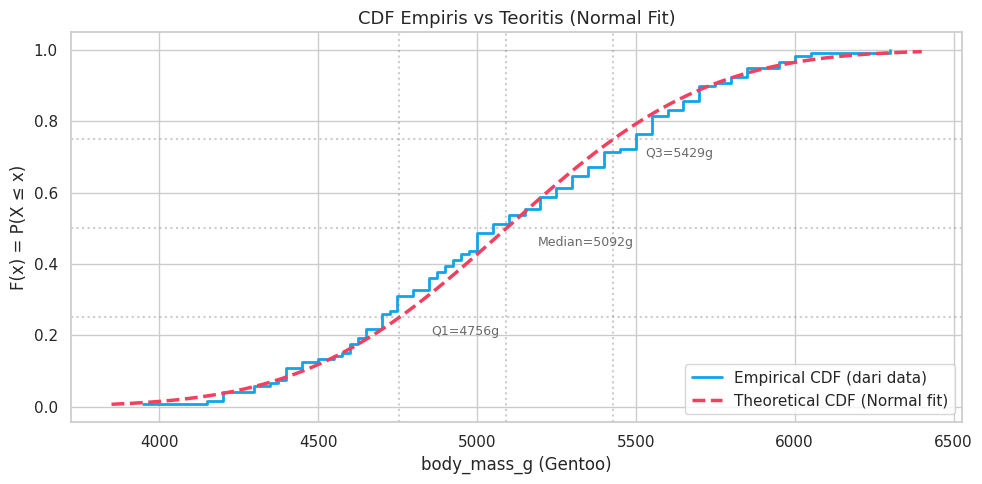

In [12]:
# Empirical CDF
sorted_mass = np.sort(gentoo_mass)
empirical_cdf = np.arange(1, len(sorted_mass) + 1) / len(sorted_mass)

# Theoretical CDF from Normal fit
x_range = np.linspace(sorted_mass.min() - 100, sorted_mass.max() + 100, 300)
theoretical_cdf = norm.cdf(x_range, loc=mu, scale=sigma)

# Plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.step(sorted_mass, empirical_cdf, where='post', linewidth=2,
        color='#0EA5E9', label='Empirical CDF (dari data)')
ax.plot(x_range, theoretical_cdf, '--', linewidth=2.5,
        color='#F43F5E', label=f'Theoretical CDF (Normal fit)')

# Mark quartiles
for q, label in [(0.25, 'Q1'), (0.50, 'Median'), (0.75, 'Q3')]:
    xq = norm.ppf(q, loc=mu, scale=sigma)
    ax.axhline(q, color='gray', linestyle=':', alpha=0.4)
    ax.axvline(xq, color='gray', linestyle=':', alpha=0.4)
    ax.annotate(f'{label}={xq:.0f}g', xy=(xq, q), xytext=(xq + 100, q - 0.05),
                fontsize=9, color='dimgray')

ax.set_xlabel('body_mass_g (Gentoo)', fontsize=12)
ax.set_ylabel('F(x) = P(X ≤ x)', fontsize=12)
ax.set_title('CDF Empiris vs Teoritis (Normal Fit)', fontsize=13)
ax.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()


## F.2 Aplikasi CDF: Quantile & Percentile


In [13]:
# Percentile calculations dengan CDF
print("Percentile Berat Gentoo (menggunakan Normal fit):\n")
for percentile in [10, 25, 50, 75, 90, 95, 99]:
    q = percentile / 100
    weight = norm.ppf(q, loc=mu, scale=sigma)
    print(f"  Percentile {percentile:3d}% (P(X ≤ x) = {q}): {weight:6.0f} gram")

print(f"\n{'='*55}")
print("Pertanyaan praktis:")
print(f"{'='*55}")

# Q1: Berapa peluang Gentoo dengan berat > 5500g?
p_over_5500 = 1 - norm.cdf(5500, loc=mu, scale=sigma)
print(f"P(Gentoo > 5500g)          = {p_over_5500:.4f}  ({p_over_5500*100:.1f}%)")

# Q2: Berapa berat pada percentile 95?
p95 = norm.ppf(0.95, loc=mu, scale=sigma)
print(f"Berat pada percentile 95   = {p95:.0f} gram")

# Q3: Percentile berapa untuk berat 5000g?
percentile_5000 = norm.cdf(5000, loc=mu, scale=sigma) * 100
print(f"Berat 5000g ada di percentile {percentile_5000:.1f}%")


Percentile Berat Gentoo (menggunakan Normal fit):

  Percentile  10% (P(X ≤ x) = 0.1):   4452 gram
  Percentile  25% (P(X ≤ x) = 0.25):   4756 gram
  Percentile  50% (P(X ≤ x) = 0.5):   5092 gram
  Percentile  75% (P(X ≤ x) = 0.75):   5429 gram
  Percentile  90% (P(X ≤ x) = 0.9):   5732 gram
  Percentile  95% (P(X ≤ x) = 0.95):   5914 gram
  Percentile  99% (P(X ≤ x) = 0.99):   6254 gram

Pertanyaan praktis:
P(Gentoo > 5500g)          = 0.2072  (20.7%)
Berat pada percentile 95   = 5914 gram
Berat 5000g ada di percentile 42.7%


---

# 🤖 G. LLM Temperature Sampling — LATIHAN UTAMA

**Tujuan Pembelajaran 4** — Implementasi Softmax dengan temperature.

## G.1 Softmax dengan Temperature

$$P(\text{token}_i) = \frac{\exp(z_i / T)}{\sum_j \exp(z_j / T)}$$

- **T rendah** (→ 0): distribusi tajam, token top hampir pasti terpilih
- **T tinggi** (→ ∞): distribusi rata, semua token sama peluang


In [14]:
def softmax_temperature(logits, T=1.0):
    """
    Softmax dengan temperature.

    Parameters:
    -----------
    logits : array-like
        Skor mentah dari model LLM
    T : float
        Temperature parameter (T > 0)

    Returns:
    --------
    probs : array
        Distribusi probabilitas token
    """
    logits = np.array(logits, dtype=float)
    scaled = logits / T
    # Trick numerik: kurangi max supaya stable
    scaled = scaled - scaled.max()
    exp_scaled = np.exp(scaled)
    return exp_scaled / exp_scaled.sum()

# Test dengan contoh sederhana
# Skenario: LLM diminta melengkapi "Kucing suka ..."
tokens = ['ikan', 'nasi', 'susu', 'tidur', 'main']
logits = [3.0, 2.5, 1.8, 2.1, 1.5]

print("Logits mentah dari model:")
for tok, z in zip(tokens, logits):
    print(f"  {tok:8s}: {z}")

print(f"\n{'='*55}")
print("Efek Temperature pada distribusi probabilitas:")
print(f"{'='*55}")

for T in [0.1, 0.5, 1.0, 2.0, 5.0]:
    probs = softmax_temperature(logits, T=T)
    print(f"\nT = {T}:")
    for tok, p in zip(tokens, probs):
        bar = '█' * int(p * 40)
        print(f"  {tok:8s}: {p:.4f}  {bar}")


Logits mentah dari model:
  ikan    : 3.0
  nasi    : 2.5
  susu    : 1.8
  tidur   : 2.1
  main    : 1.5

Efek Temperature pada distribusi probabilitas:

T = 0.1:
  ikan    : 0.9932  ███████████████████████████████████████
  nasi    : 0.0067  
  susu    : 0.0000  
  tidur   : 0.0001  
  main    : 0.0000  

T = 0.5:
  ikan    : 0.5975  ███████████████████████
  nasi    : 0.2198  ████████
  susu    : 0.0542  ██
  tidur   : 0.0988  ███
  main    : 0.0297  █

T = 1.0:
  ikan    : 0.3941  ███████████████
  nasi    : 0.2390  █████████
  susu    : 0.1187  ████
  tidur   : 0.1602  ██████
  main    : 0.0879  ███

T = 2.0:
  ikan    : 0.2909  ███████████
  nasi    : 0.2266  █████████
  susu    : 0.1596  ██████
  tidur   : 0.1855  ███████
  main    : 0.1374  █████

T = 5.0:
  ikan    : 0.2343  █████████
  nasi    : 0.2120  ████████
  susu    : 0.1843  ███████
  tidur   : 0.1957  ███████
  main    : 0.1736  ██████


## G.2 Visualisasi Efek Temperature


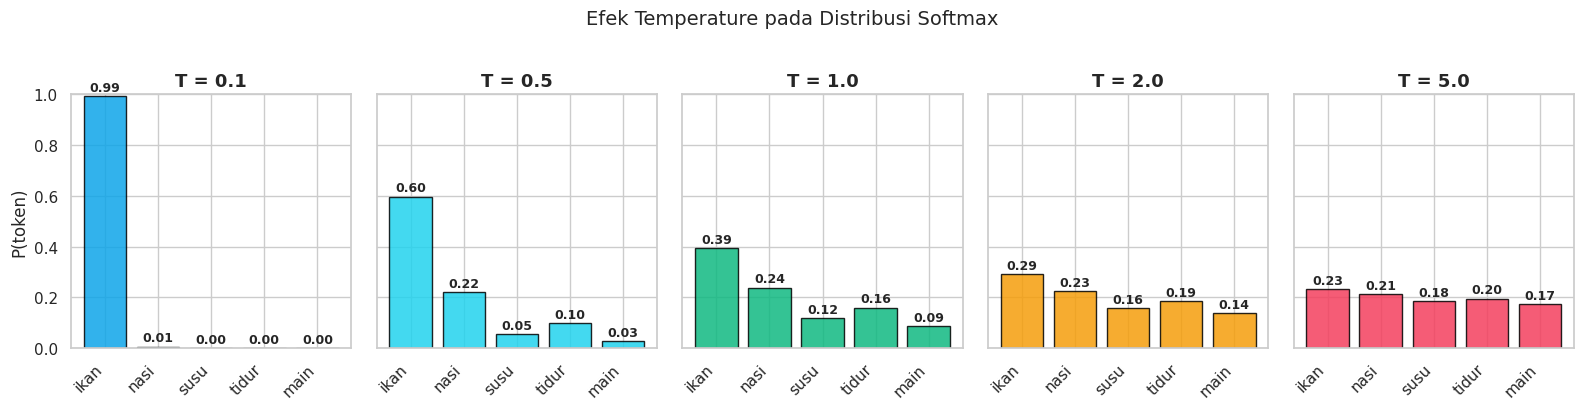

Kesimpulan:
• T = 0.1 → 'ikan' hampir pasti dipilih (deterministik)
• T = 1.0 → distribusi natural, sesuai logits
• T = 5.0 → hampir uniform, model sangat kreatif/acak


In [15]:
# Visualisasi comparative
temperatures = [0.1, 0.5, 1.0, 2.0, 5.0]

fig, axes = plt.subplots(1, len(temperatures), figsize=(16, 4), sharey=True)
colors_temp = ['#0EA5E9', '#22D3EE', '#10B981', '#F59E0B', '#F43F5E']

for ax, T, c in zip(axes, temperatures, colors_temp):
    probs = softmax_temperature(logits, T=T)
    ax.bar(tokens, probs, color=c, edgecolor='black', alpha=0.85)
    ax.set_title(f'T = {T}', fontsize=13, fontweight='bold')
    ax.set_ylim(0, 1)
    for i, p in enumerate(probs):
        ax.text(i, p + 0.02, f'{p:.2f}', ha='center', fontweight='bold', fontsize=9)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

axes[0].set_ylabel('P(token)', fontsize=12)
plt.suptitle('Efek Temperature pada Distribusi Softmax', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("Kesimpulan:")
print("• T = 0.1 → 'ikan' hampir pasti dipilih (deterministik)")
print("• T = 1.0 → distribusi natural, sesuai logits")
print("• T = 5.0 → hampir uniform, model sangat kreatif/acak")


## G.3 Simulasi Sampling: 100× Lempar Dadu Token


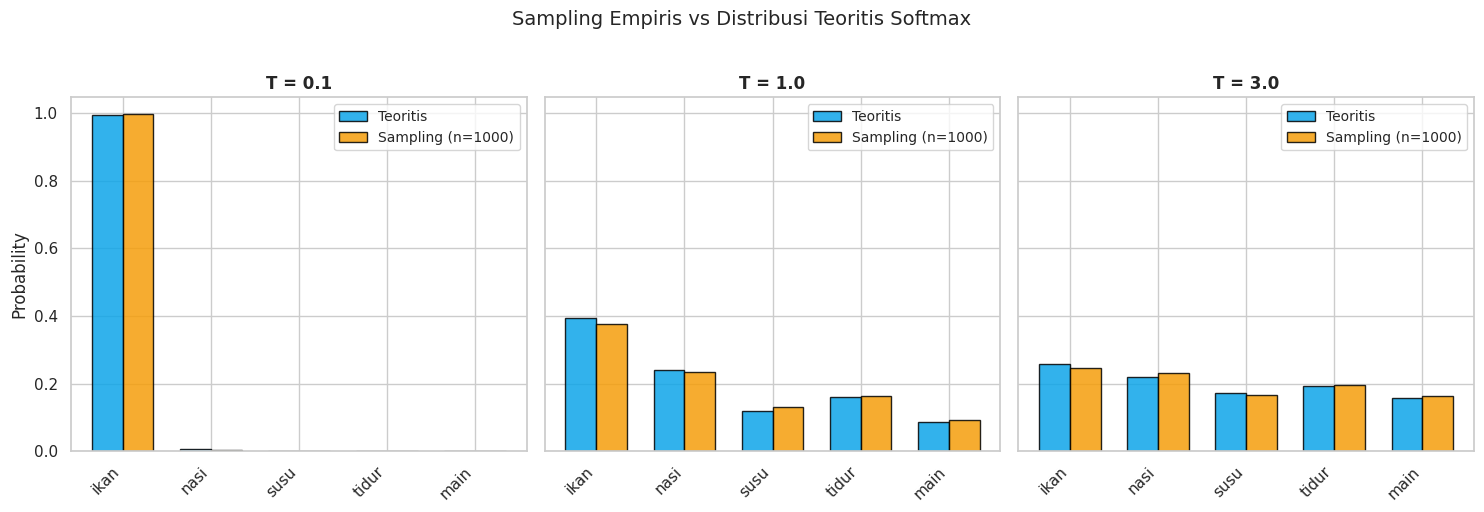

Amati:
• T rendah: hampir semua sample = 'ikan'
• T tinggi: sample lebih terdistribusi merata
• Empiris (kuning) hampir sama dengan teoritis (biru) → sampling correct!


In [16]:
np.random.seed(42)

def sample_token(logits, tokens, T=1.0, n_samples=100):
    """Simulasi sampling n token dari distribusi Softmax(T)."""
    probs = softmax_temperature(logits, T=T)
    samples = np.random.choice(tokens, size=n_samples, p=probs)
    return samples

# Sampling dengan 3 temperature
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, T in zip(axes, [0.1, 1.0, 3.0]):
    samples = sample_token(logits, tokens, T=T, n_samples=1000)
    counts = pd.Series(samples).value_counts().reindex(tokens, fill_value=0)
    empirical = counts / counts.sum()
    theoretical = softmax_temperature(logits, T=T)

    x = np.arange(len(tokens))
    width = 0.35
    ax.bar(x - width/2, theoretical, width, label='Teoritis',
           color='#0EA5E9', alpha=0.85, edgecolor='black')
    ax.bar(x + width/2, empirical, width, label='Sampling (n=1000)',
           color='#F59E0B', alpha=0.85, edgecolor='black')
    ax.set_xticks(x)
    ax.set_xticklabels(tokens, rotation=45, ha='right')
    ax.set_title(f'T = {T}', fontsize=12, fontweight='bold')
    ax.legend(fontsize=10)

axes[0].set_ylabel('Probability', fontsize=12)
plt.suptitle('Sampling Empiris vs Distribusi Teoritis Softmax', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("Amati:")
print("• T rendah: hampir semua sample = 'ikan'")
print("• T tinggi: sample lebih terdistribusi merata")
print("• Empiris (kuning) hampir sama dengan teoritis (biru) → sampling correct!")


## G.4 Latihan Anda: Eksperimen Temperature Sendiri

Ubah `logits` dan `T` di bawah untuk melihat efeknya:


In [17]:
# LATIHAN — ganti nilai berikut dan lihat efeknya!
my_tokens = ['Jakarta', 'Bali', 'Bandung', 'Surabaya', 'Medan']
my_logits = [4.0, 2.5, 2.8, 2.3, 1.8]     # <-- ubah nilai ini
my_T      = 1.0                              # <-- ubah temperature (0.1 - 5.0)

# Hitung distribusi
probs = softmax_temperature(my_logits, T=my_T)

print(f"Prompt: 'Kota di Indonesia adalah ...'")
print(f"Temperature: T = {my_T}\n")

for tok, p in zip(my_tokens, probs):
    bar = '█' * int(p * 50)
    print(f"  {tok:10s}: {p:.4f}  {bar}")

# Sample 20 tokens
np.random.seed(0)
samples = np.random.choice(my_tokens, size=20, p=probs)
print(f"\n20 sampel: {list(samples)}")


Prompt: 'Kota di Indonesia adalah ...'
Temperature: T = 1.0

  Jakarta   : 0.5501  ███████████████████████████
  Bali      : 0.1227  ██████
  Bandung   : 0.1657  ████████
  Surabaya  : 0.1005  █████
  Medan     : 0.0610  ███

20 sampel: [np.str_('Jakarta'), np.str_('Bandung'), np.str_('Bali'), np.str_('Jakarta'), np.str_('Jakarta'), np.str_('Bali'), np.str_('Jakarta'), np.str_('Surabaya'), np.str_('Medan'), np.str_('Jakarta'), np.str_('Bandung'), np.str_('Jakarta'), np.str_('Bali'), np.str_('Surabaya'), np.str_('Jakarta'), np.str_('Jakarta'), np.str_('Jakarta'), np.str_('Bandung'), np.str_('Bandung'), np.str_('Surabaya')]


> ✏️ **Coba**:
> - Set `my_T = 0.1` — apa yang terjadi?
> - Set `my_T = 5.0` — apa yang terjadi?
> - Ubah `my_logits[0]` ke 10 — bagaimana distribusinya?


---

# 📝 H. Refleksi & Submit

## H.1 Pertanyaan Refleksi

Jawab 5 pertanyaan di cell markdown di bawah:

1. **Diskret vs Kontinu**: Kenapa jumlah klik di iklan disebut variabel diskret, sedangkan waktu response API kontinu?

2. **E(X)**: Kalau E(body_mass_Gentoo) = 5076g, apa artinya bagi peneliti biologi? Bagaimana angka ini bisa berguna?

3. **PDF**: Kenapa nilai PDF di titik tunggal (misal f(5000) = 0.0005) BUKAN probabilitas? Kapan PDF menjadi probabilitas?

4. **CDF**: Sebutkan 1 aplikasi CDF di industri (finance, healthcare, dll) dan jelaskan singkat.

5. **LLM Temperature**: Kalau Anda membangun chatbot customer service, temperature berapa yang cocok? Kalau untuk generator cerita fiksi?

### ✏️ Jawaban Anda:

**1.** Jumlah klik pada iklan disebut variabel diskret karena dihitung dalam bilangan bulat, seperti 0, 1, 2, dan seterusnya. Sementara itu, waktu respons API disebut variabel kontinu karena dapat diukur dalam rentang nilai, termasuk angka desimal, seperti 0,25 detik atau 1,75 detik.

**2.** Jika E(body_mass_Gentoo) = 5076 gram, artinya rata-rata berat tubuh penguin spesies Gentoo yang diharapkan adalah sekitar 5076 gram. Nilai ini berguna bagi peneliti biologi untuk mengetahui karakteristik berat tubuh penguin, membandingkan berat antarspesies, serta memantau kondisi dan pertumbuhan penguin.

**3.** Nilai PDF pada satu titik, misalnya f(5000) = 0.0005, bukan merupakan probabilitas karena PDF menunjukkan kepadatan probabilitas pada suatu nilai, bukan peluang tepat pada nilai tersebut. Probabilitas diperoleh dengan menghitung luas di bawah kurva PDF pada suatu interval. Untuk variabel kontinu, probabilitas pada satu nilai tepat adalah nol.

**4.** Salah satu penerapan CDF di industri keuangan adalah menghitung peluang kerugian investasi berada di bawah batas tertentu. Dengan CDF, perusahaan dapat mengetahui proporsi kemungkinan kerugian yang tidak melebihi nilai tertentu sehingga dapat membantu analisis risiko dan pengambilan keputusan investasi.

**5.** Untuk chatbot customer service, temperature rendah, misalnya 0.2, cocok digunakan karena menghasilkan jawaban yang lebih konsisten, terarah, dan tidak terlalu bervariasi. Sementara itu, untuk generator cerita fiksi, temperature lebih tinggi, misalnya 0.8, cocok digunakan karena menghasilkan jawaban yang lebih beragam, kreatif, dan imajinatif.

## H.2 Checklist Submit

Sebelum submit, pastikan:

- [ ] Semua cell code berhasil dijalankan tanpa error
- [ ] Latihan B.3 sudah diisi (klasifikasi 5 variabel baru)
- [ ] Latihan G.4 sudah dicoba dengan minimal 2 nilai temperature berbeda
- [ ] 5 pertanyaan refleksi sudah dijawab
- [ ] Notebook di-rename: `M4-Praktikum-VariabelAcak-NamaAnda.ipynb`
- [ ] Download dari Colab (File → Download → .ipynb)
- [ ] Upload ke GitHub repository Anda
- [ ] Link GitHub dikumpulkan via LMS Uniska

## H.3 Push ke GitHub

**Melalui Web:**
1. Buka repository `statistika-probabilitas-uniska` di GitHub Anda.
2. Klik folder `notebooks/`, lalu **Add file → Upload files**.
3. Drag & drop file notebook.
4. Commit message: `"Add Modul 4: Variabel Acak & LLM Sampling"`.
5. Klik **Commit changes**.

---

## 🎓 Selamat! Anda Berhasil...

✅ Membedakan variabel acak diskret dan kontinu di data nyata (Palmer Penguins)  
✅ Menghitung E(X) dan Var(X) per spesies + verifikasi sifat linearitas  
✅ Memvisualisasikan PMF, PDF, CDF dengan scipy.stats  
✅ Implementasi Softmax + Temperature — memahami cara LLM sampling  

## 📚 Bacaan Lanjutan

- **Bruce, P.** (2020). *Practical Statistics for Data Scientists*, Chapter 2 (Data & Sampling Distributions).
- **VanderPlas, J.** (2023). *Python Data Science Handbook*, Section 4 (Visualization).
- **OpenAI Cookbook** — [Temperature and sampling parameters](https://cookbook.openai.com).

## 🔮 Persiapan Modul 5

Modul 5 mendalami **distribusi diskret spesifik**:
- Distribusi Bernoulli & Binomial
- Distribusi Poisson  
- A/B Testing Netflix/Tokopedia
- DDoS detection via Poisson

**Tugas Mandiri sebelum M5:**
1. Selesaikan Modul-4.ipynb, push ke GitHub
2. Baca Bruce Ch. 2 (Data & Sampling Distributions)
3. Kaggle Learn "Intermediate ML" (~5 jam)

---

*Notebook by: Prodi Teknik Informatika · Uniska MAB Banjarmasin · Edisi 2026*
